langkah adalah seperti biasa menyiapkan library library atau alat alat yang akan digunakan untuk melakukan task
numpy disini adalh bertugas untuk array angka untuk dipakai membuat data titik
pandas adalah untuk mengelola data bertipe tabel
linkage menghitung penggabungan bertahap
dendrogram adlah untuk pembuatan pohonnya
pdist disini untuk menghitung jarak antar titik
squareform disini untuk mengubah datanya menjadi hasil tabel persegi

In [1]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt

Selanjutnya langkah dibawah adalah bertujuan untuk membuat data set di berbagai posisi

In [2]:
# 1. Dataset sederhana
data = np.array([
 [1.0, 1.0], # a
 [1.5, 1.5], # b
 [5.0, 5.0], # c
 [3.0, 4.0], # d
 [4.0, 4.0], # e
 [3.0, 3.5] # f
])

langkah dibawah adalah untuk mengihitung jarak semua pasangan dan disusun oleh squareform menjadi tabel

In [3]:
# 2. Hitung Distance Matrix (Euclidean Distance)
distance_matrix = pdist(data, metric='euclidean')
distance_df = pd.DataFrame(squareform(distance_matrix),
 columns=['a', 'b', 'c', 'd', 'e', 'f'],
 index=['a', 'b', 'c', 'd', 'e', 'f'])

langkah ini adalah untuk menampilkan tabel jarak

In [4]:
# 3. Tampilkan Distance Matrix
print("=== Distance Matrix (Euclidean) ===")
print(distance_df)

=== Distance Matrix (Euclidean) ===
          a         b         c         d         e         f
a  0.000000  0.707107  5.656854  3.605551  4.242641  3.201562
b  0.707107  0.000000  4.949747  2.915476  3.535534  2.500000
c  5.656854  4.949747  0.000000  2.236068  1.414214  2.500000
d  3.605551  2.915476  2.236068  0.000000  1.000000  0.500000
e  4.242641  3.535534  1.414214  1.000000  0.000000  1.118034
f  3.201562  2.500000  2.500000  0.500000  1.118034  0.000000


langkah ini adalah langkah untuk menggabungkan titik terdekat secara bertahap

In [5]:
# 4. Hierarchical Clustering (Single Linkage)
linked = linkage(data, method='single')

langkah berikut adalaah menggambar pohon penggabungan  yang telah dibuatkan tadi

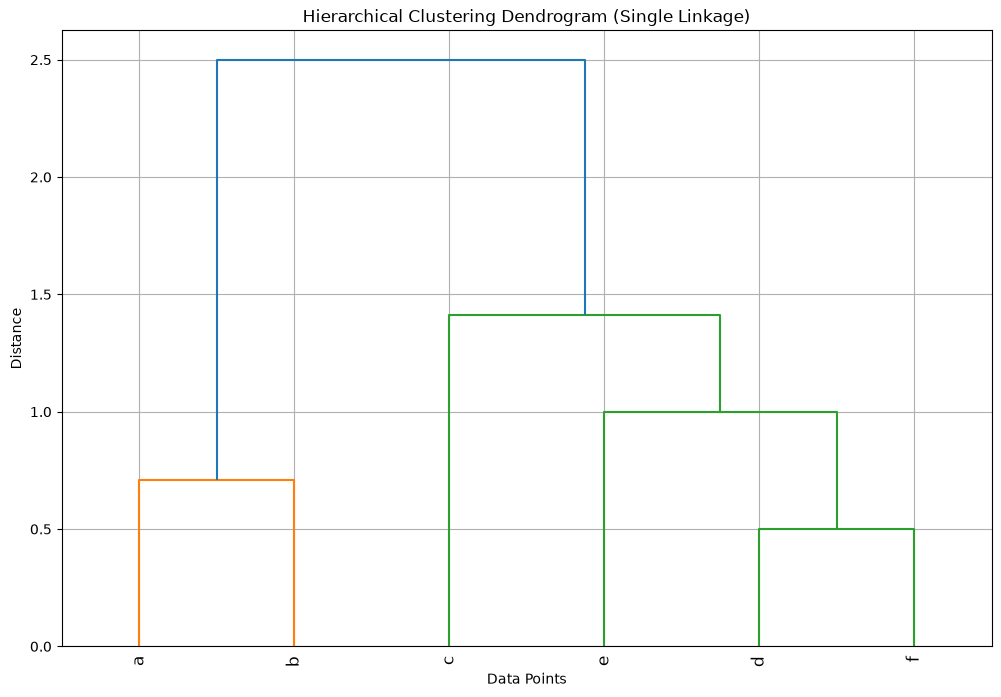

In [6]:
# 5. Plot Dendrogram
plt.figure(figsize=(12, 8))
plt.title("Hierarchical Clustering Dendrogram (Single Linkage)")
dendrogram(linked, labels=['a', 'b', 'c', 'd', 'e', 'f'], leaf_rotation=90)
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.grid(True)
plt.show()

langkah pertama dibawah ini  adalah langkah untuk  menyiapkan librari dan data yang akan digunakan

In [9]:

import pandas as pd
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


mengambil colom income dan spending score kedalam bentuk array

In [10]:
x = df.iloc[:, [3, 4]].values

mengubah data menjadi rata rata 0 dan simpangan bakunya jadi 1

In [11]:
from sklearn.preprocessing import StandardScaler
data_scaler = StandardScaler()
scaled_data = data_scaler.fit_transform(x)
scaled_data.shape


(200, 2)

langkah dibawah adalah untuk membangun hierarki dengan complate linkage

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram
clustering = linkage(scaled_data, method="complete", metric="euclidean")

membagi kelompok pohon menjadi 3 warna yaitu orange, hijau, ,merah

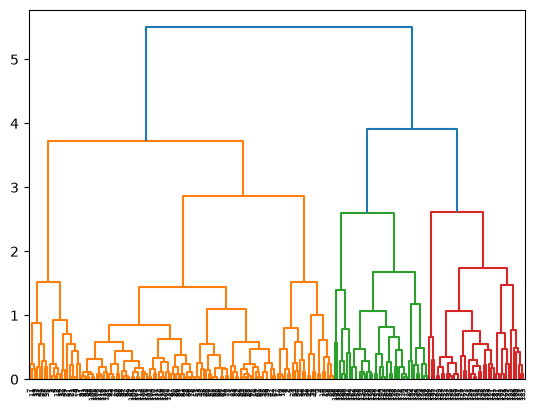

In [13]:
import matplotlib.pyplot as plt
dendrogram(clustering)
plt.show()

# TUGAS PRAKTIKUM SESI #

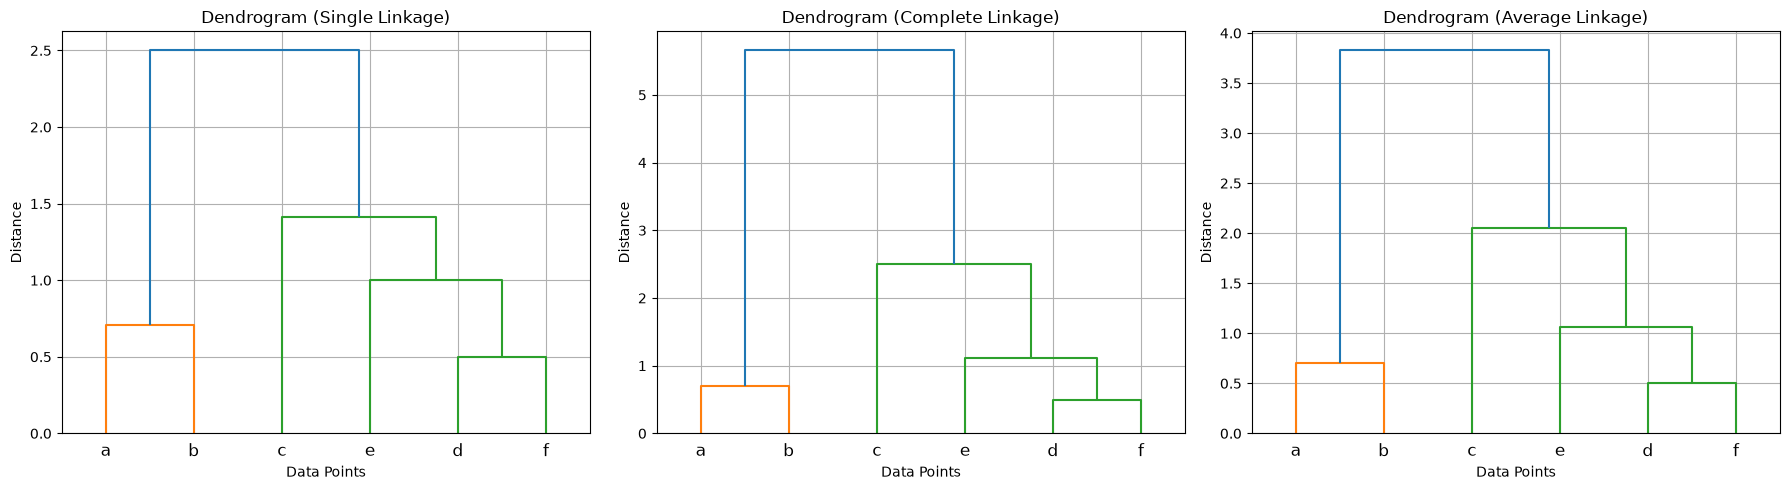

In [14]:
metode = ['single', 'complete', 'average']

plt.figure(figsize=(18, 5))
for i, m in enumerate(metode):
    plt.subplot(1, 3, i + 1)
    linked = linkage(data, method=m)
    dendrogram(linked, labels=['a', 'b', 'c', 'd', 'e', 'f'])
    plt.title(f"Dendrogram ({m.capitalize()} Linkage)")
    plt.xlabel("Data Points")
    plt.ylabel("Distance")
    plt.grid(True)
plt.tight_layout()
plt.show()

ketiga metode menghasilkan urutan penggabungan yang sama pada data seet sederhana ini, tetapi berbeda pada jarak penggabungan, sigle linkage menghasilakan jarak terrendah, complete linkage menghasilkan jarak tertinggi, dan  yang terakhit avarage berada diantara keduanya. berdasarkan yang aku pelajari kedepannya untuk pemilihan metode itu tergantung pada data dimana single cocok untuk bentuk kelompok yang memanjang, complete untuk kelompok yang kompak, dan avarage nya untuk piliha yang seimbang diatara keduanya